In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data -O data-week-4.csv

--2026-10-27 01:15:36--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘data-week-4.csv’

data-week-4.csv     100%[===================>] 272.21K  --.-KB/s    in 0.03s   

2026-10-27 01:15:36 (7.75 MB/s) - ‘data-week-4.csv’ saved [278746/278746]



In [3]:
df = pd.read_csv('data-week-4.csv')

In [4]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
categorical = list(df.dtypes[df.dtypes == 'str'].index)
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [8]:
numerical = list(df.dtypes[(df.dtypes == 'int') | (df.dtypes == 'float')].index)
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [9]:
for c in categorical:
    df[c] = df[c].fillna('NA')

In [10]:
for n in numerical:
    df[n] = df[n].fillna(0)

In [11]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train,
    test_size=0.25,
    random_state=1
)

In [13]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [14]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted
y_val = df_val.converted
y_test = df_test.converted

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [15]:
numerical = [
    n
    for n in numerical
    if n != 'converted'
]

numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

### Question 1: ROC AUC feature importance

In [16]:
from sklearn.metrics import roc_auc_score

In [17]:
for n in numerical:
    if n == 'converted':
        continue

    score = roc_auc_score(y_train, df_train[n])

    print(f'score with {n}: {score}')

score with annual_income: 0.6081977776250831
score with number_of_courses_viewed: 0.7229894623989618
score with interaction_count: 0.7649203047563227
score with lead_score: 0.7882254810906102


In [18]:
# lead_score

### Question 2: Training the model

In [19]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [20]:
dv = DictVectorizer(sparse=False)

dicts = df_train[categorical + numerical].to_dict(orient='records')
X_trian = dv.fit_transform(dicts)

dv

DictVectorizer(sparse=False)

In [21]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_trian, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [22]:
dicts_val = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(dicts_val)

y_pred = model.predict_proba(X_val)[:, 1]

In [23]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

In [24]:
# 0.732

### Question 3: Precision and Recall

In [25]:
thresholds = np.linspace(0, 1, 101)
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [26]:
# Precision = TP / (TP + FP)
# Recall = TP / (TP + FN)

In [27]:
y_val

0      0
1      1
2      1
3      1
4      0
      ..
995    1
996    1
997    1
998    1
999    0
Name: converted, Length: 1000, dtype: int64

In [28]:
scores = []

precisions = []
recalls = []

for threshold in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predicted_positive = (y_pred >= threshold)
    predicted_negative = (y_pred < threshold)

    tp = (predicted_positive & actual_positive).sum()
    tn = (predicted_negative & actual_negative).sum()
    fp = (predicted_positive & actual_negative).sum()
    fn = (predicted_negative & actual_positive).sum()

    if tp > 0:
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
    else:
        precision = 0
        recall = 0

    scores.append([threshold, precision, recall])

    precisions.append(precision)
    recalls.append(recall)

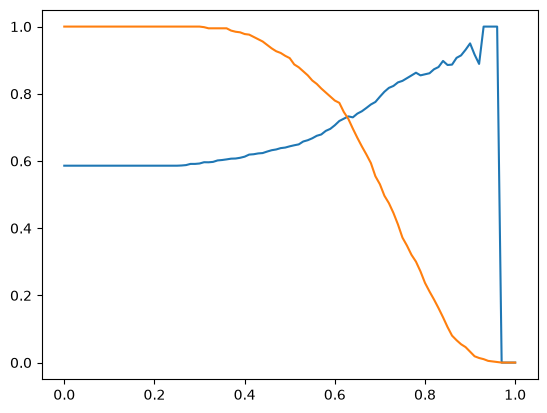

In [29]:
plt.plot(thresholds, precisions, label='Precision')
plt.plot(thresholds, recalls, label='Recall')


In [30]:
for t, precision, recall in scores:
    print(f't={t.round(2)}:\t{precision - recall}')

t=0.0:	-0.41400000000000003
t=0.01:	-0.41400000000000003
t=0.02:	-0.41400000000000003
t=0.03:	-0.41400000000000003
t=0.04:	-0.41400000000000003
t=0.05:	-0.41400000000000003
t=0.06:	-0.41400000000000003
t=0.07:	-0.41400000000000003
t=0.08:	-0.41400000000000003
t=0.09:	-0.41400000000000003
t=0.1:	-0.41400000000000003
t=0.11:	-0.41400000000000003
t=0.12:	-0.41400000000000003
t=0.13:	-0.41400000000000003
t=0.14:	-0.41400000000000003
t=0.15:	-0.41400000000000003
t=0.16:	-0.41400000000000003
t=0.17:	-0.41400000000000003
t=0.18:	-0.41400000000000003
t=0.19:	-0.41400000000000003
t=0.2:	-0.41400000000000003
t=0.21:	-0.41400000000000003
t=0.22:	-0.41400000000000003
t=0.23:	-0.41400000000000003
t=0.24:	-0.41400000000000003
t=0.25:	-0.41400000000000003
t=0.26:	-0.4134134134134134
t=0.27:	-0.4122367101303912
t=0.28:	-0.408678102926337
t=0.29:	-0.408678102926337
t=0.3:	-0.40748230535894847
t=0.31:	-0.401963240129004
t=0.32:	-0.39876602664768246
t=0.33:	-0.39754448050131486
t=0.34:	-0.393229359284579

In [31]:
# 0.63

### Question 4: F1 score

In [32]:
f1_scores = []

for t, precision, recall in scores:
    if precision == 0 and recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    f1_scores.append(f1)

    print(f't={t.round(2)}:\t{f1}')

t=0.0:	0.7389659520807063
t=0.01:	0.7389659520807063
t=0.02:	0.7389659520807063
t=0.03:	0.7389659520807063
t=0.04:	0.7389659520807063
t=0.05:	0.7389659520807063
t=0.06:	0.7389659520807063
t=0.07:	0.7389659520807063
t=0.08:	0.7389659520807063
t=0.09:	0.7389659520807063
t=0.1:	0.7389659520807063
t=0.11:	0.7389659520807063
t=0.12:	0.7389659520807063
t=0.13:	0.7389659520807063
t=0.14:	0.7389659520807063
t=0.15:	0.7389659520807063
t=0.16:	0.7389659520807063
t=0.17:	0.7389659520807063
t=0.18:	0.7389659520807063
t=0.19:	0.7389659520807063
t=0.2:	0.7389659520807063
t=0.21:	0.7389659520807063
t=0.22:	0.7389659520807063
t=0.23:	0.7389659520807063
t=0.24:	0.7389659520807063
t=0.25:	0.7389659520807063
t=0.26:	0.7394321766561515
t=0.27:	0.7403663929248262
t=0.28:	0.7431832593532023
t=0.29:	0.7431832593532023
t=0.3:	0.7441269841269841
t=0.31:	0.7466496490108486
t=0.32:	0.7455242966751919
t=0.33:	0.7464788732394367
t=0.34:	0.74983922829582
t=0.35:	0.7508048937540245
t=0.36:	0.752258064516129
t=0.37:	

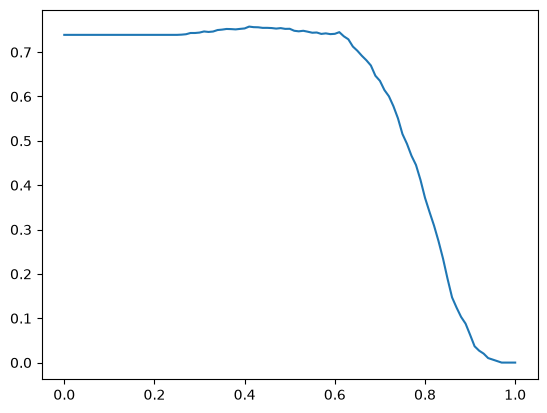

In [33]:
plt.plot(thresholds, f1_scores)

In [34]:
# 0.41

### Question 5: 5-Fold CV

In [35]:
from sklearn.model_selection import KFold

In [36]:
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
...,...,...,...,...,...,...,...,...,...
2895,paid_ads,manufacturing,NA,north_america,66121.0,1,1,0.20,0
2763,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
905,NA,manufacturing,NA,NA,49820.0,2,3,0.44,0
3980,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


In [37]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [39]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted']
    y_val = df_val['converted']

    dv, model = train(df_train, y_train, C=1.0)
    y_pred = predict(df_val, dv, model)

    score = roc_auc_score(y_val, y_pred)

    scores.append(score)

In [40]:
scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [44]:
np.std(scores)

np.float64(0.006853233151022138)

In [45]:
np.std(scores).round(3)

np.float64(0.007)

In [46]:
# 0.007

### Question 6: Hyperparameter Tuning

In [47]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:

    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
    
        y_train = df_train['converted']
        y_val = df_val['converted']
    
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
    
        score = roc_auc_score(y_val, y_pred)
    
        scores.append(score)

    print(f'C={C}: mean={np.mean(scores)}, std={np.std(scores)}')

C=1e-06: mean=0.6167342250714795, std=0.018669799234831475
C=0.001: mean=0.7491721776030379, std=0.009996375455700753
C=1: mean=0.7317269710972524, std=0.006853233151022138


In [48]:
# C=0.001